# Оценка частоты дыхания по видео

## 1. Цель и условия записи

Оцениваю частоту дыхания RR по движению центральной области груди. Один вдох и следующий за ним выдох считаю одним циклом. Исследую запись с изменяющимся направлением освещения, движениями руки и корпуса.

Примерно с 65 с использую фонарик телефона в правой руке и перемещаю его. Разделяю сведения о сценарии и видимые события: в 64,5–66,5 с вижу вытягивание руки и смещение плеч; в 128–131 с вижу телефон и заметное усиление освещения лица и одежды. Точный момент включения и выключения света по обзорным кадрам не подтверждаю. До этого тоже вижу повороты головы и изменения позы. Условия низкой освещённости, смену цвета экрана и видеофильтры не рассматриваю как проведённые эксперименты.

Вычислительную часть выполняю полностью. Для точности относительно дыхания сохраняю ограничение: независимый подтверждённый ручной эталон отсутствует, поэтому MAE и ошибки отдельных дыхательных циклов не оцениваю.

## 2. Архитектура

Выбираю OpenPose COCO и SelFlow из исходной схемы. По плечам ограничиваю центральную область груди, чтобы сократить вклад движущейся руки. SelFlow оценивает двумерное движение текстуры одежды по трём кадрам. Сохраняю горизонтальную и вертикальную составляющие, а для подсчёта заранее выбираю вертикальное движение: при данном ракурсе подъём груди имеет вертикальную проекцию. По горизонтальному каналу проверяю сопутствующее движение.

По сравнению с яркостью одного участка поток даёт направление и масштаб видимого движения. При этом движущийся свет и тени тоже могут создавать ложное движение текстуры. Контроль уверенности плеч, разброса потока и просмотра кадров сохраняю как часть анализа качества; не считаю их заменой эталона.

Matplotlib is building the font cache; this may take a moment.


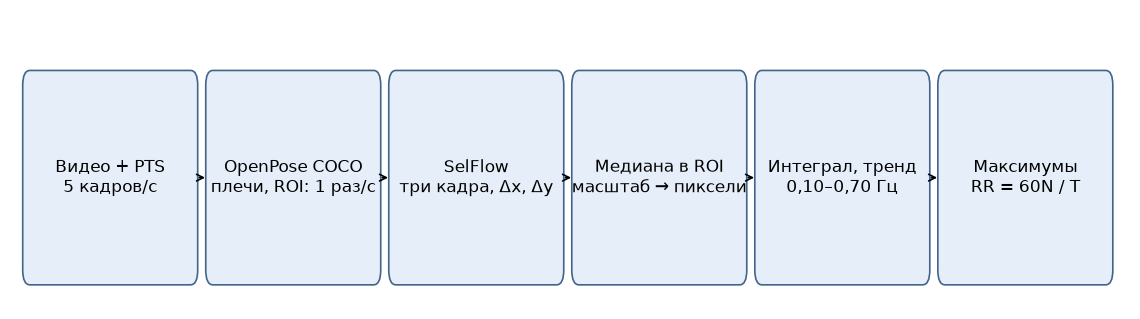

In [1]:
import os, sys, json, csv
from pathlib import Path
os.environ.setdefault('MPLCONFIGDIR', str(Path('cache/mpl').resolve()))
os.environ.setdefault('XDG_CACHE_HOME', str(Path('cache').resolve()))
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
ROOT = Path.cwd()
assert (ROOT / 'data/raw/ml-breath.mov').is_file(), 'Запускаю из breathing_lab/'
sys.path.insert(0, str(ROOT / 'scripts'))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from pipeline import fingerprint, run_full, write_json
from audit_video import audit
from analysis import analyze
from figures import table, architecture, sample_frames, pose_frames, overview, comparisons, diagnostics, problem_frames, events
from checks import verify
display(architecture()); plt.close('all')

Применяю предобученную OpenPose COCO для определения ключевых точек и SelFlow с весами `Sintel/supervise_finetune` для оценки движения. Использую обе модели без дополнительного обучения. Для одной видимой фигуры выбираю максимумы карт ключевых точек.

## 3. Параметры видео и временная шкала

Определяю разрешение, число кадров, кодек и длительность записи. Временную шкалу строю по фактическим отметкам кадров: при расчёте RR использую реальную длительность участка, а не округлённую частоту 30 кадров/с. Ниже показываю примеры до использования фонарика, во время перехода и при последующих изменениях освещения.

параметр,значение
"Ширина, пикс.",1280
"Высота, пикс.",720
"Частота кадров, кадр/с",29.996
Кодек,h264
Число кадров,4587
"Длительность, с",152.918


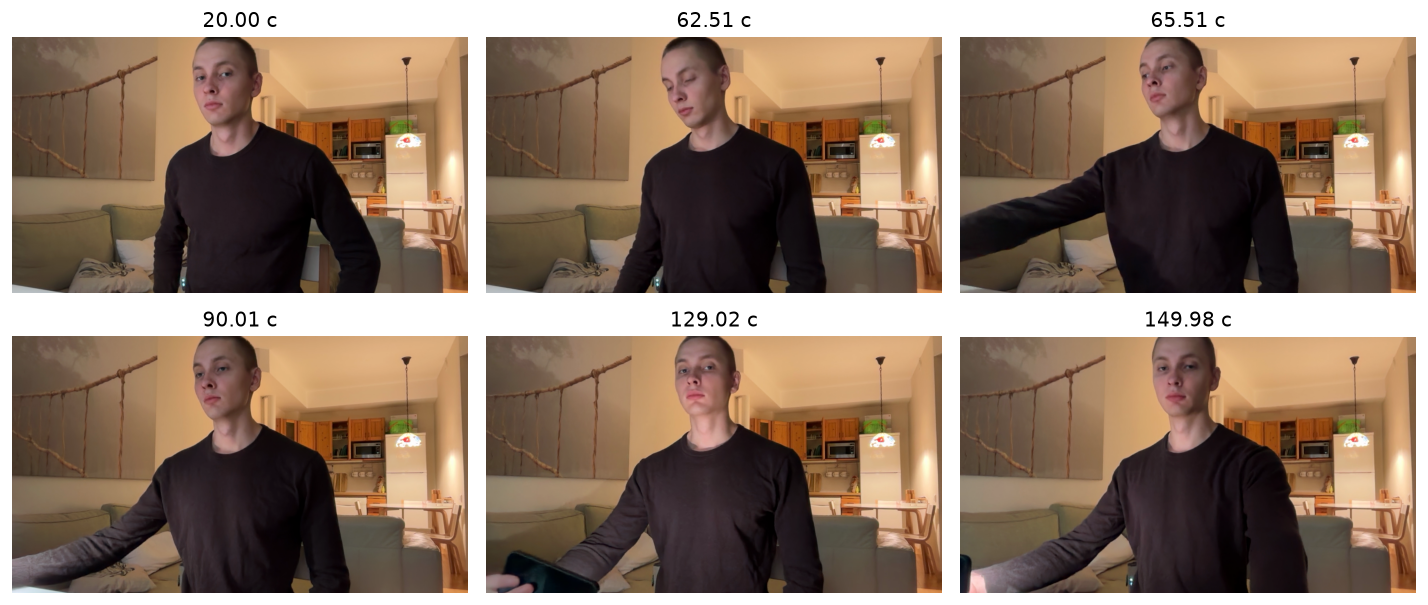

In [2]:
video = audit()
expected = json.loads(Path('review/metadata.json').read_text())
assert abs(video['duration_pts_s'] - expected['duration']) < 0.001
assert video['sha256'] == '43aa0a110c6b4030f2cdba431ac7c4bb75e839966e2750183f94549d1580f2f8'
table([{'параметр': name, 'значение': video[key]} for name, key in [
    ('Ширина, пикс.', 'width'), ('Высота, пикс.', 'height'),
    ('Частота кадров, кадр/с', 'fps'), ('Кодек', 'fourcc'),
    ('Число кадров', 'decoded_frames'), ('Длительность, с', 'duration_pts_s')]])
display(sample_frames()); plt.close('all')

Получаю 4587 кадров размером 1280 × 720, H.264 в контейнере MOV, 29,996457 кадра/с. Длительность записи равна 152,91806 с. Все кадры декодируются; промежутки между ними составляют 0,03333–0,03335 с. На примерах различаю поворот головы до фонарика, переход с вытягиванием руки и позднее изменение освещения.

## 4. Разметка и правила подсчёта

Использую вспомогательные отметки для сопоставления с сигналом. Независимый подтверждённый ручной эталон RR в текущих данных отсутствует. Не называю число вспомогательных точек истинным числом вдохов и не подбираю под него параметры детектора.

Для независимой разметки просматриваю исходное видео и отмечаю один и тот же момент каждого цикла — конец вдоха. Неоднозначные участки выделяю отдельно; подтверждаю отметки после просмотра всей записи.

Для детектора использую соглашение о событиях: считаю максимум сигнала, если его время принадлежит полуоткрытому окну `[a, b)`. Событие на правой границе отношу к следующему окну. Считаю RR как `60 × N / (b − a)`. Максимум движения пока не отождествляю с подтверждённым концом вдоха; физиологическую фазу нужно проверить по независимому просмотру. Неполные циклы у границ не добавляю вручную.

In [3]:
auxiliary = list(csv.DictReader(Path('annotations/breath-cycle-assisted.csv').open()))
print('Вспомогательных отметок:', len(auxiliary))
print('Независимый подтверждённый файл:', Path('annotations/manual-confirmed.json').exists())
intervals = events()
table(intervals, ['start_seconds', 'end_seconds', 'event', 'description', 'evidence', 'boundary_uncertainty_s'])

Вспомогательных отметок: 45
Независимый подтверждённый файл: False


start_seconds,end_seconds,event,description,evidence,boundary_uncertainty_s
0,7.5,body_arm,Меняются положение плеч и изгиб рук у корпуса,video_observation_sampled_frames,2.5
7.5,17.5,head,Голова и взгляд поворачиваются вверх и в сторону,video_observation_sampled_frames,2.5
20,25,arm_body,Меняются положение руки и наклон верхней части корпуса,video_observation_sampled_frames,2.5
27.5,37.5,head,Меняются направление взгляда и поворот головы,video_observation_sampled_frames,2.5
42.5,47.5,arm_body,Рука у нижней границы кадра; небольшое изменение позы,video_observation_sampled_frames,2.5
62,63.5,head,Голова наклоняется вниз и возвращается,video_observation_sampled_frames,0.5
64.5,66.5,arm_body,Правая рука вытягивается влево в изображении; смещаются плечи и корпус,video_observation_sampled_frames,0.5
65,152.91805,torch_scenario,Использую движущийся фонарик телефона в правой руке примерно с 65 с; точные моменты включения и выключения не подтверждаю,user_scenario_approximate,2
66.5,152.91805,arm,Правая рука остаётся вытянутой и меняет положение; часть телефона вне кадра,video_observation_sampled_frames,0.5
128,131,light_shadow_phone,Телефон виден у левого края; заметно усиливается освещение лица и меняются светлые участки на рукаве и груди,video_observation_sampled_frames,0.5


Отделяю интервалы видимых движений от приблизительного сценарного интервала фонарика. По обзорным кадрам отмечаю границы с неопределённостью 0,35–2,5 с; это не покадровая разметка каждого движения. В частности, не делаю вывод, что фонарик выключается перед концом записи: такого события не подтверждаю. Отсутствие интервала в таблице не доказывает отсутствие помех.

## 5. Ключевые точки, область груди и оценка смещений

По точкам COCO 2 и 5 нахожу середину плеч `(cx, cy)` и расстояние между ними `d` в исходных пикселях. Выбираю прямоугольник `x ∈ [cx − 0,36d, cx + 0,36d]`, `y ∈ [cy + 0,18d, cy + 0,80d]`. Обновляю его раз в секунду по плечам; так область следует за корпусом и остаётся внутри центральной части одежды. Для плеч требую уверенность не ниже 0,15. При кратком пропуске сохраняю последнюю область; длительные пропуски потребовали бы исключения участка. Проверяю, возникают ли они на данной записи.

Для оценки движения выбираю 5 кадров/с по фактическим временным отметкам; ключевые точки обновляю раз в секунду. Уменьшаю изображение до 384 × 216 пикселей и дополняю его снизу до 384 × 256. SelFlow получает тройку соседних выбранных кадров и возвращает поток от центрального к следующему. Между ключевыми точками сохраняю последнюю ROI, но сам поток оцениваю в общей системе изображения. Масштаб по обеим осям равен 0,3; добавление 40 строк снизу до 256 не меняет координат тела. Возвращаю смещения в исходные пиксели делением на 0,3.

Кадров с определёнными плечами: 153 / 153


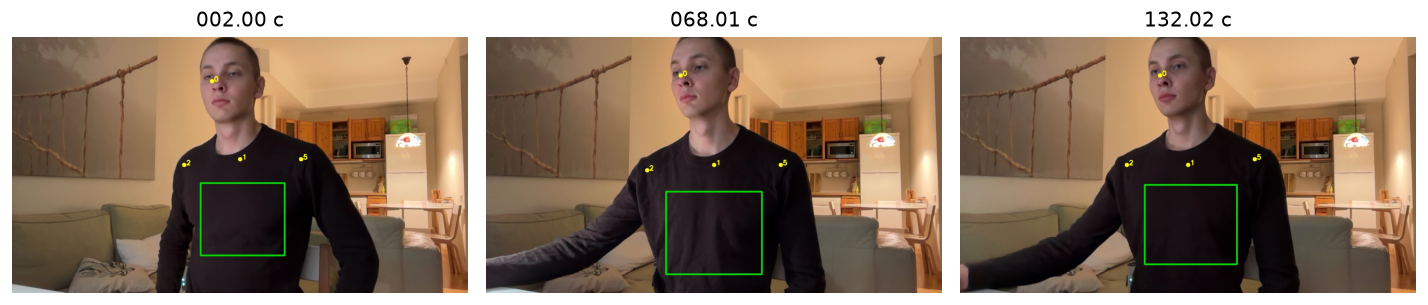

In [4]:
cache = run_full()
assert json.loads((cache / 'manifest.json').read_text()) == fingerprint()
poses = json.loads((cache / 'poses.json').read_text())
print('Кадров с определёнными плечами:', sum(p['valid'] for p in poses), '/', len(poses))
display(pose_frames()); plt.close('all')

Для всей записи получаю 153 оценки ключевых точек и 763 пары смещений. В 153 из 153 проверок оба плеча проходят порог; минимальная уверенность плеч равна 0.359. На показанных кадрах ROI лежит на центральной части груди; точки таза не использую, поскольку нижняя часть тела обрезана.

## 6. Проверка направления и единиц потока

Проверяю сеть на первом реальном кадре, искусственно сдвигая его на 0 и ±6 пикселей по каждой оси. Использую ту же предобработку и ту же ROI. Проверяю восстановленный масштаб, знак и поперечную составляющую. В изображении положительный `u` направлен вправо, положительный `v` — вниз. Для графика подъёма груди меняю знак вертикальной составляющей. Пиксели не перевожу в миллиметры: калибровки расстояния и 3D-движения нет.

In [5]:
translation = json.loads(Path('results/translation_check.json').read_text())
table(translation)
max_translation_error = max(max(abs(r['measured_u_px'] - r['expected_u_px']),
                                abs(r['measured_v_px'] - r['expected_v_px'])) for r in translation)
assert max_translation_error < 1.0
print('Максимальная абсолютная ошибка синтетического сдвига, пикс.:', max_translation_error)

expected_u_px,expected_v_px,measured_u_px,measured_v_px
0,0,-0.000,0.002
6,0,6.065,0.011
-6,0,-6.047,0.048
0,6,0.010,6.201
0,-6,-0.056,-6.127


Максимальная абсолютная ошибка синтетического сдвига, пикс.: 0.20068836212158203


Для горизонтальных ±6 пикселей получаю 6.065 и -6.047; для вертикальных — 6.201 и -6.127. Максимальная ошибка компоненты равна 0.201 пикселя. На неподвижной тройке получаю смещения по модулю менее 0,003 пикселя. Проверка подтверждает знак и пересчёт масштаба в этом примере, но не доказывает точность на субпиксельном дыхании и при движущихся тенях.

## 7. Одномерный сигнал и дыхательные максимумы

Для каждой пары кадров беру пространственную медиану `u` и `v` внутри ROI. Суммирую смещения: `x = Σu`, `y = −Σv`. Это условные интегралы медианного поля, а не траектория одной физической точки. Если использую скорость, делю смещение на фактическое `Δt`; при интегрировании умножаю её обратно на то же `Δt`.

Интерполирую интегралы на равномерную сетку 5 Гц по сохранённым PTS. Удаляю линейный тренд и применяю Butterworth третьего порядка 0,10–0,70 Гц с двунаправленной фильтрацией. Полоса соответствует 6–42 циклам/мин и задаёт диапазон поиска, а не измеренную норму. Нулевую фазу получаю ценой использования будущих кадров, поэтому это обработка после записи.

В вертикальном канале нахожу максимумы с расстоянием не менее 1,4 с и prominence 0,35 от робастного масштаба `1,4826 × MAD` всей записи. Сохраняю одинаковый абсолютный порог для всех окон. Для первых и последних 5 с отдельно учитываю возможное влияние границ фильтра.

Параметры сигнала: {'low_hz': 0.1, 'high_hz': 0.7, 'fs_hz': 5.0, 'min_distance_s': 1.4, 'prominence_mad': 0.35}
Порог prominence, пикс.: 0.7305420872948154
Доступный интервал PTS, с: 0.20003 152.81804000000002


duration_s,n_peaks,RR_est_bpm,dominant_bpm,filtered_rms_px,band_concentration
152.618,46,18.084,17.277,2.454,0.718


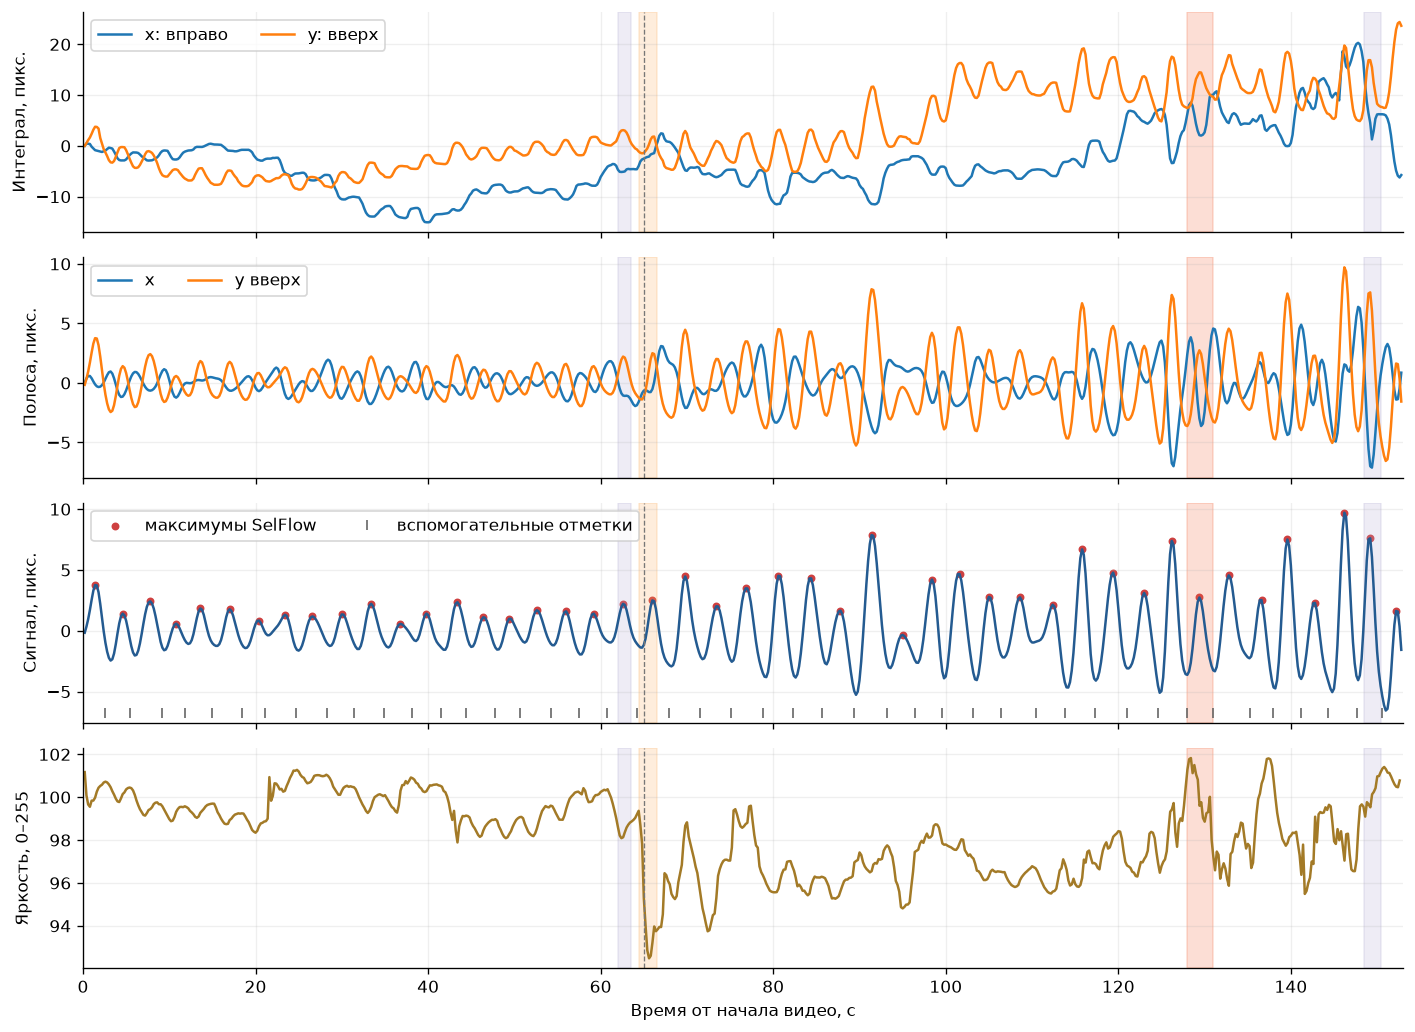

In [6]:
data, summary = analyze(cache)
print('Параметры сигнала:', summary['config'])
print('Порог prominence, пикс.:', summary['peak_prominence_px'])
print('Доступный интервал PTS, с:', summary['signal_start_s'], summary['signal_end_s'])
table([summary['full']], ['duration_s', 'n_peaks', 'RR_est_bpm', 'dominant_bpm', 'filtered_rms_px', 'band_concentration'])
display(overview(data)); plt.close('all')

Получаю 46 максимумов за 152.61801 с доступного сигнала, то есть оценку RR 18.08 мин⁻¹. Это результат детектора, а не подтверждённое число дыхательных циклов. Использую фактический интервал 0.20003–152.81804 с: для трёхкадрового метода не экстраполирую отсутствующие приращения у концов видео. Запись длиннее этого интервала на 0.30005 с.

Доминирующая частота в полосе равна 17.28 мин⁻¹. Её отличие от подсчёта максимумов допускает непостоянный период и влияние формы сигнала; по нему одному не определяю ошибку RR. Среднюю яркость считаю по серому изображению всего кадра в шкале 0–255; она не измеряет освещённость в люксах. Затенённые интервалы показывают наблюдаемые движения и изменение освещения; пунктир обозначает приблизительную отметку 65 с из сценария.

## 8. Сравнение одинаковых временных окон

Сравниваю 2–32 и 32–62 с до фонарика с 72–102 и 102–132 с во время его перемещения. Каждое окно имеет длительность 30 с; переход 62–72 с исключаю из сопоставления. Считаю события по единому сигналу и единому порогу, не фильтрую окна независимо.

Кроме RR показываю RMS сигнала, медианный пространственный разброс векторов и концентрацию спектральной мощности в пределах ±0,05 Гц от доминирующей частоты внутри полосы. Последний показатель не называю SNR и не использую как точность. При 30 с частотное разрешение равно 2 мин⁻¹.

window,duration_s,n_peaks,RR_est_bpm,dominant_bpm,filtered_rms_px,flow_dispersion_px,band_concentration,brightness_range
до: 2–32,30.000,9,18.000,20.000,1.114,0.079,0.635,2.931
до: 32–62,30.000,9,18.000,18.000,1.054,0.081,0.779,3.029
фонарик: 72–102,30.000,9,18.000,16.000,2.869,0.230,0.632,5.856
фонарик: 102–132,30.000,8,16.000,18.000,2.829,0.203,0.800,6.319


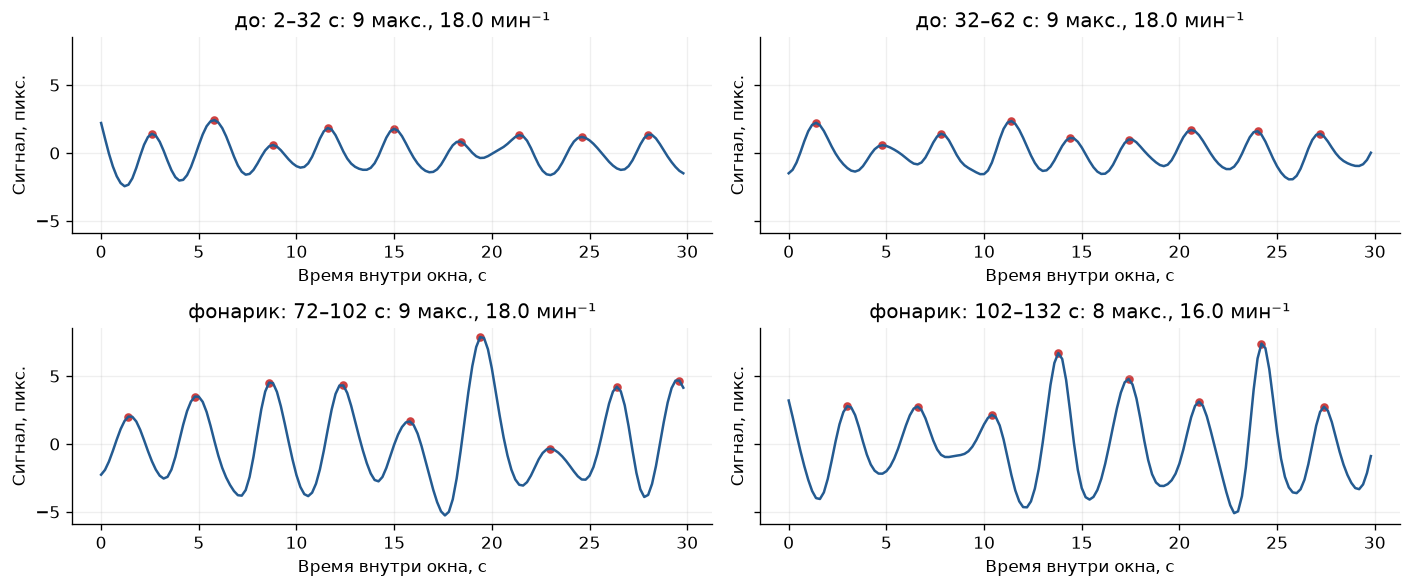

window,duration_s,n_peaks,RR_est_bpm
0.2–30.2,30.000,10,20.000
30.2–60.2,30.000,9,18.000
60.2–90.2,30.000,8,16.000
90.2–120.2,30.000,9,18.000
120.2–150.2,30.000,9,18.000
150.2–152.8,2.618,1,22.918


In [7]:
table(summary['comparable_windows'], ['window', 'duration_s', 'n_peaks', 'RR_est_bpm', 'dominant_bpm',
      'filtered_rms_px', 'flow_dispersion_px', 'band_concentration', 'brightness_range'])
display(comparisons(data, summary)); plt.close('all')
table(summary['grid'], ['window', 'duration_s', 'n_peaks', 'RR_est_bpm'])

В двух окнах до фонарика получаю 9 и 9 максимумов (18 и 18 мин⁻¹); во время перемещения — 9 и 8 (18 и 16 мин⁻¹). Средний RMS для этих пар окон меняется с 1.084 до 2.849 пикселя, а разброс потока — с 0.080 до 0.216 пикселя.

Увеличение движения вижу в этих данных, но не связываю его только с освещением: одновременно меняются положение руки, корпуса и, возможно, само дыхание. Сохранение периодической составляющей и близких оценок RR не доказывает отсутствие ошибок. Короткий остаток записи в последней строке общей таблицы не сравниваю с 30-секундными окнами: один максимум в таком окне сильно меняет оценку.

## 9. Проблемные интервалы и анализ ограничений

Рассматриваю 60–70, 124–136 и 145–152,8 с вместе с кадрами. В 62–63,5 с вижу наклон головы; в 64,5–66,5 с — вытягивание руки и смещение плеч; в 128–131 с — телефон и усиление освещения; в 148,5–150,5 с — движение второй руки и приближение корпуса.

Проверяю, совпадают ли изменения сигнала с этими событиями. Формулирую возможные причины как гипотезы: общий сдвиг тела, изменение ROI и движение световых границ могут попадать в дыхательную полосу после интегрирования и фильтрации. Само наличие этих факторов не доказывает ложный или пропущенный вдох.

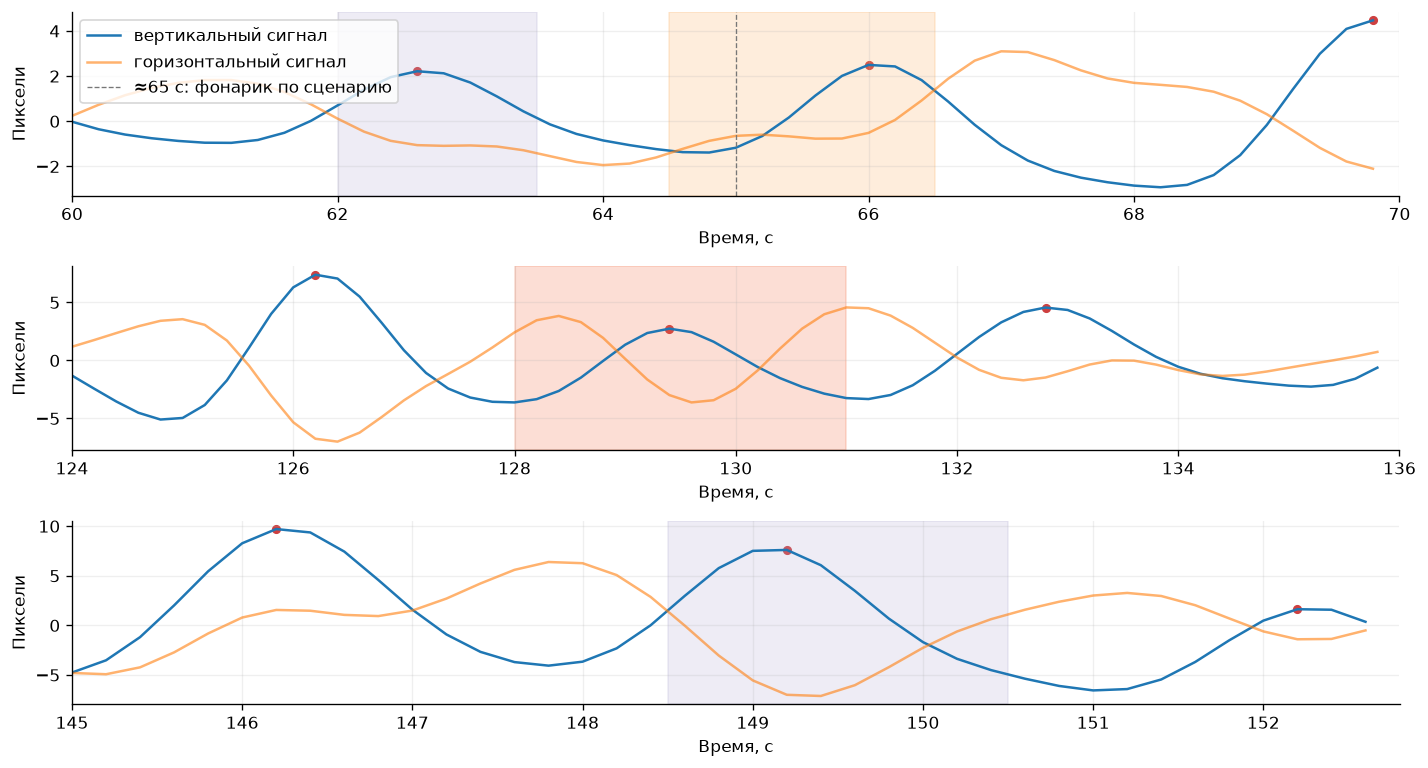

"интервал, с","max |Δy|, пикс./пару","медиана разброса, пикс.",максимумов
60.0–70.0,1.699,0.171,3
124.0–136.0,3.852,0.264,3
145.0–152.8,4.121,0.364,3


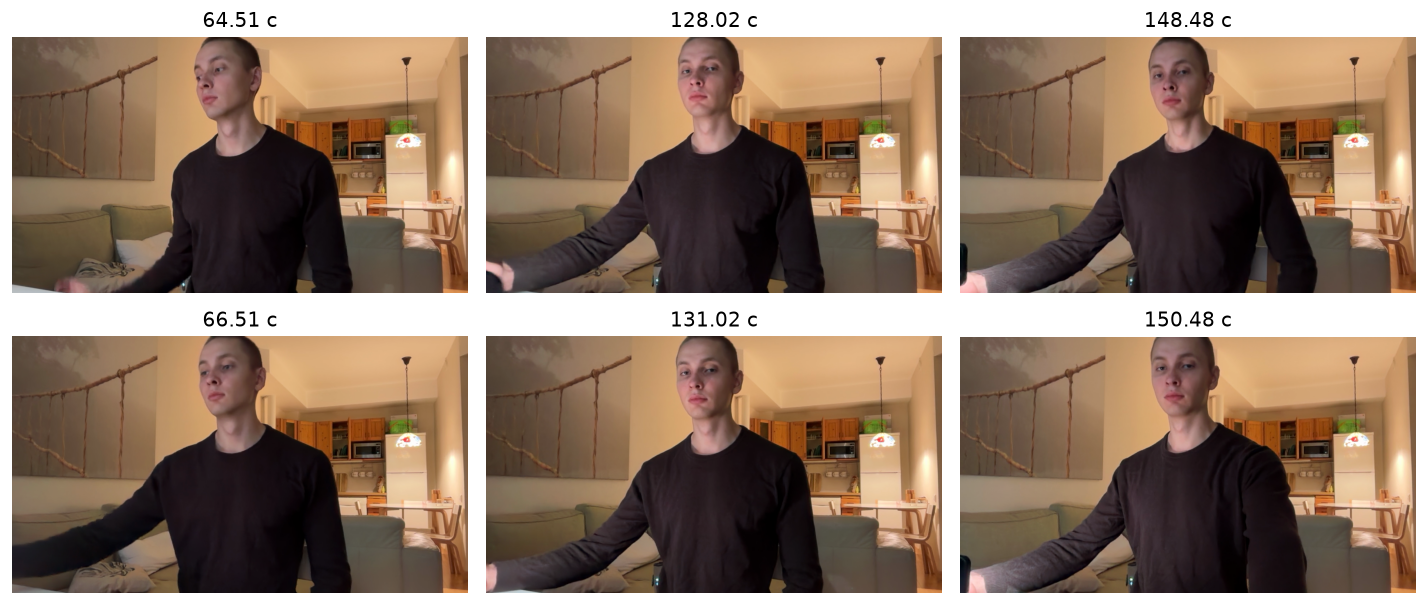

In [8]:
display(diagnostics(data)); plt.close('all')
problem_rows = []
for a, b in [(60., 70.), (124., 136.), (145., 152.8)]:
    rr = [r for r in data['records'] if a <= r['time'] < b]
    problem_rows.append({'интервал, с': f'{a}–{b}',
                         'max |Δy|, пикс./пару': max(abs(r['v']) for r in rr),
                         'медиана разброса, пикс.': float(np.median([r['flow_mad_px'] for r in rr])),
                         'максимумов': int(np.sum((data['peaks'] >= a) & (data['peaks'] < b)))})
table(problem_rows)
display(problem_frames()); plt.close('all')

На парах кадров показываю состояние до и после выделенных событий. На графиках сопоставляю вертикальную и горизонтальную проекции. Выделяю эти интервалы как требующие проверки, а не как доказанные ошибки подсчёта. Не могу надёжно перечислить пропущенные и ложные дыхательные циклы без независимой разметки одного и того же физиологического события. Если движение корпуса совпадает с дыханием по частоте, одной полосовой фильтрации недостаточно для их разделения.

Проверяю чувствительность детектора к prominence 0,20; 0,35; 0,50 и 0,80 MAD. Это оценка зависимости от параметра, а не подбор под число вспомогательных отметок.

In [9]:
table(summary['sensitivity'])
checks = verify(data)
write_json(Path('results/checks.json'), checks)
accuracy = summary['accuracy']
if accuracy['status'] == 'evaluated':
    table(accuracy['windows'])
    print('MAE RR:', accuracy['RR_MAE'], 'мин⁻¹; смещение:', accuracy['RR_bias'], 'мин⁻¹')
else:
    print('MAE, смещение и ошибки отдельных циклов не вычисляю: независимый эталон не подтверждён.')

prominence_mad,n_peaks,RR_est_bpm
0.200,46,18.084
0.350,46,18.084
0.500,46,18.084
0.800,43,16.905


MAE, смещение и ошибки отдельных циклов не вычисляю: независимый эталон не подтверждён.


При проверенных порогах получаю от 43 до 46 максимумов. Такая устойчивость или чувствительность характеризует этот детектор на одной записи и не заменяет проверку истинных циклов.

Для оценки точности оставляю явный статус «независимый эталон не подтверждён». Сравнение ошибок RR до и во время фонарика, а также подтверждение конкретных пропусков остаются недоступными по текущим данным.

## 10. Выводы

Реализую и выполняю OpenPose COCO, отслеживание области груди, трёхкадровый SelFlow с исходными весами, обе проекции движения, удаление тренда, полосовую фильтрацию и подсчёт максимумов. Для полного видео сохраняю координаты, PTS, смещения, сигналы, графики и таблицы. Масштаб и направление потока подтверждаю на контролируемых сдвигах.

Для доступного сигнала получаю оценку RR 18.08 мин⁻¹ по 46 максимумам. В сопоставимых окнах вижу изменение амплитуды и пространственного разброса движения. Не делаю вывода об изолированном влиянии света: одновременно действуют движения рук и корпуса. По одной записи не оцениваю общую точность метода.

Ограничиваю вывод об эффективности: независимого подтверждённого эталона нет, поэтому не получаю MAE RR, чувствительность детекции дыхательных циклов и доказанный список ошибок. Вспомогательные отметки использую только для визуального сопоставления. Нейросетевая вычислительная часть завершена; требование о независимой ручной проверке точности пока не закрываю.